# Windows-focused Cybersecurity Threat Intelligence Knowledge Graph

This notebook reproduces the analysis from Turtle ontology.

In [1]:
%pip install rdflib pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Load the ontology and instance files

In [2]:
from rdflib import Graph
import pandas as pd
import matplotlib.pyplot as plt

ontology_url = "https://raw.githubusercontent.com/Timoseee/windows-cyber-threat-kg/main/windows-cyber-threat-ontology.ttl"
# The GitHub URLs below can be replaced with paths to local TTL files containing the same data.
# Example: r"C:\your_folder\windows-cyber-threat-ontology.ttl"
instances_url = "https://raw.githubusercontent.com/Timoseee/windows-cyber-threat-kg/main/windows-cyber-threat-instances.ttl"
g = Graph()#load files tp the graph
g.parse(ontology_url, format="turtle")
g.parse(instances_url, format="turtle")

<Graph identifier=N20d0606374494add9e00bc89e28264c9 (<class 'rdflib.graph.Graph'>)>

## 2. CVE analysis

This query lists each CVE, its severity, its CWE weakness, and the affected Windows products.

In [3]:
cve_query = """
PREFIX cti: <https://github.com/Timoseee/windows-cyber-threat-kg/ontology#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT DISTINCT ?cve_name ?severity_name ?weakness_name ?product_name
WHERE {
    ?cve a cti:Vulnerability;
         rdfs:label ?cve_name;
         cti:hasSeverity ?severity;
         cti:hasWeakness ?weakness;
         cti:affectsProduct ?product.
    ?severity rdfs:label ?severity_name.
    ?weakness rdfs:label ?weakness_name.
    ?product rdfs:label ?product_name.
}
ORDER BY ?cve_name ?product_name
"""
cve_rows = []#get all the cve and put them to this array
for row in g.query(cve_query):
    cve_rows.append({
        "CVE ID": str(row.cve_name),
        "Severity": str(row.severity_name),
        "Weakness": str(row.weakness_name),
        "Affected Windows product": str(row.product_name)
    })

cve_df = pd.DataFrame(cve_rows).drop_duplicates()
cve_df

,CVE ID,Severity,Weakness,Affected Windows product
0,CVE-2024-30051,HIGH severity,CWE-122,windows_10_1507 *
1,CVE-2024-30051,HIGH severity,CWE-787,windows_10_1507 *
2,CVE-2024-30051,HIGH severity,CWE-122,windows_10_1607 *
3,CVE-2024-30051,HIGH severity,CWE-787,windows_10_1607 *
4,CVE-2024-30051,HIGH severity,CWE-122,windows_10_1809 *
5,CVE-2024-30051,HIGH severity,CWE-787,windows_10_1809 *
6,CVE-2024-30051,HIGH severity,CWE-122,windows_10_21h2 *
7,CVE-2024-30051,HIGH severity,CWE-787,windows_10_21h2 *
8,CVE-2024-30051,HIGH severity,CWE-122,windows_10_22h2 *
9,CVE-2024-30051,HIGH severity,CWE-787,windows_10_22h2 *


In [4]:
summary = (cve_df.groupby(["CVE ID", "Severity"])["Affected Windows product"].nunique().reset_index(name="Affected product count"))
summary

,CVE ID,Severity,Affected product count
0,CVE-2024-30051,HIGH severity,11
1,CVE-2024-30078,HIGH severity,16
2,CVE-2024-38063,CRITICAL severity,17
3,CVE-2024-38080,HIGH severity,5


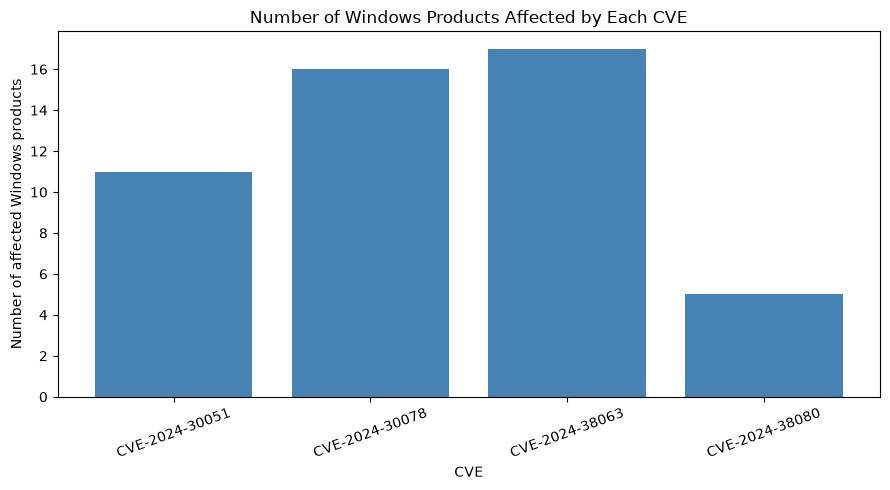

In [5]:
plt.close("all")
plt.figure(figsize=(9, 5))

x = range(len(summary))
plt.bar(x, summary["Affected product count"], color="steelblue")
plt.xticks(x, summary["CVE ID"], rotation=20)
plt.title("Number of Windows Products Affected by Each CVE")
plt.xlabel("CVE")
plt.ylabel("Number of affected Windows products")
plt.tight_layout()
plt.show()

## 3. ATT&CK technique analysis

This query counts the number of different threat actors associated with each selected Windows ATT&CK technique.

In [11]:
#Which ATT&CK techniques are used by the largest number of different threat actors?
technique_query = """
PREFIX cti: <https://github.com/Timoseee/windows-cyber-threat-kg/ontology#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?technique_name (COUNT(DISTINCT ?actor) AS ?actor_count)
WHERE {
    ?actor a cti:ThreatActor;
           cti:usesTechnique ?technique.

    ?technique rdfs:label ?technique_name.
}
GROUP BY ?technique_name
ORDER BY DESC(?actor_count)
"""

technique_rows = []
for row in g.query(technique_query):
    technique_rows.append({
        "Technique": str(row.technique_name),
        "Actor count": int(row.actor_count)
    })

technique_df = pd.DataFrame(technique_rows)
technique_df

,Technique,Actor count
0,PowerShell (T1059.001),85
1,Spearphishing Attachment (T1566.001),78
2,Windows Command Shell (T1059.003),73
3,Scheduled Task (T1053.005),54
4,Windows Management Instrumentation (T1047),42


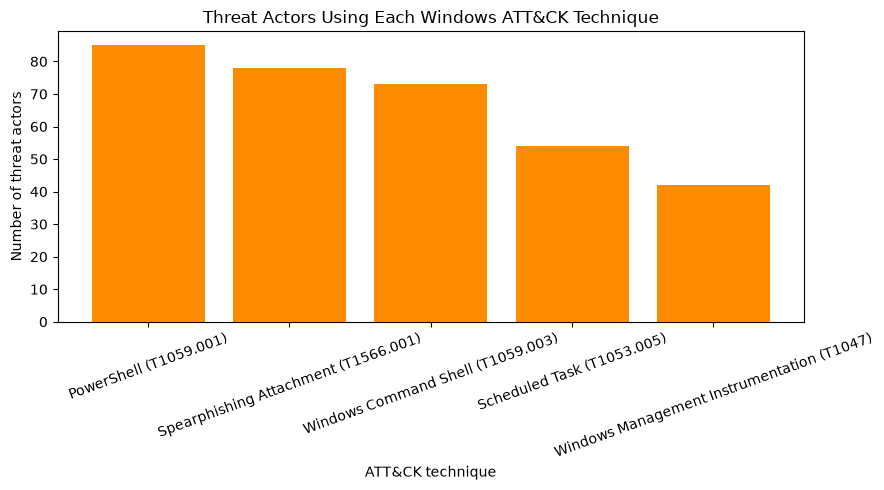

In [7]:
plt.figure(figsize=(9, 5))
x = range(len(technique_df))
plt.bar(x, technique_df["Actor count"], color="darkorange")
plt.xticks(x, technique_df["Technique"], rotation=20)
plt.title("Threat Actors Using Each Windows ATT&CK Technique")
plt.xlabel("ATT&CK technique")
plt.ylabel("Number of threat actors")
plt.tight_layout()
plt.show()

## 4. Cross-source Windows context

This query get Windows-related threat actors, techniques, CVEs, and severities all in one result table.

In [12]:
integration_query = """
PREFIX cti: <https://github.com/Timoseee/windows-cyber-threat-kg/ontology#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT DISTINCT ?category ?item ?related_item
WHERE {
    {
        ?actor a cti:ThreatActor;
            rdfs:label ?item;
            cti:usesTechnique ?technique.
        ?technique rdfs:label ?related_item;
                cti:applicableToPlatform cti:Windows.
        BIND("Actor-Technique" AS ?category)
    }
    UNION
    {
    ?cve a cti:Vulnerability;
        rdfs:label ?item;
        cti:hasSeverity ?severity;
        cti:affectsProduct ?product.
    ?severity rdfs:label ?related_item.
    ?product cti:belongsToPlatform cti:Windows.
    BIND("CVE-Severity" AS ?category)
    }

}
ORDER BY ?category ?item
"""

integration_rows = []
for row in g.query(integration_query):
    integration_rows.append({
        "Category": str(row.category),
        "Item": str(row.item),
        "Related item": str(row.related_item)
    })

integration_df = pd.DataFrame(integration_rows).drop_duplicates()
integration_df

,Category,Item,Related item
0,Actor-Technique,APT-C-36 (G0099),Windows Management Instrumentation (T1047)
1,Actor-Technique,APT-C-36 (G0099),Scheduled Task (T1053.005)
2,Actor-Technique,APT-C-36 (G0099),Spearphishing Attachment (T1566.001)
3,Actor-Technique,APT-C-36 (G0099),PowerShell (T1059.001)
4,Actor-Technique,APT1 (G0006),Windows Command Shell (T1059.003)
...,...,...,...
331,Actor-Technique,menuPass (G0045),PowerShell (T1059.001)
332,CVE-Severity,CVE-2024-30051,HIGH severity
333,CVE-Severity,CVE-2024-30078,HIGH severity
334,CVE-Severity,CVE-2024-38063,CRITICAL severity
